# 02b: ...

### Импорты и пути

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import lightgbm as lgb
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    brier_score_loss, precision_recall_curve,
    confusion_matrix, classification_report,
)
from sklearn.calibration import calibration_curve

DATA_DIR = Path("../data")
FINAL_DIR = DATA_DIR / "physical_signs_final"

In [2]:
koi = pd.read_csv(FINAL_DIR / "koi_clean.csv")

y = koi["label"].astype(int)
groups = koi["kepid"]
id_cols = ["label", "kepid", "kepoi_name"]
X = koi.drop(columns = id_cols)

### Сплит по группам

In [3]:
sgkf_holdout = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)
train_idx, test_idx = next(sgkf_holdout.split(X, y, groups=groups))

### Диагностика

In [4]:
train_kepids = set(groups.iloc[train_idx])
test_kepids = set(groups.iloc[test_idx])
overlap = train_kepids & test_kepids

print(f"Пересечение kepid между train и test: {len(overlap)}")
assert len(overlap) == 0, f"Утечка! Пересекаются kepid: {list(overlap)[:5]}"
print("Группы не пересекаются")

print(f"\nБаланс классов:")
print(f"  Train: 1 = {y.iloc[train_idx].sum()} ({y.iloc[train_idx].mean()*100:.1f}%)")
print(f"  Test:  1 = {y.iloc[test_idx].sum()} ({y.iloc[test_idx].mean()*100:.1f}%)")
assert y.iloc[test_idx].sum() > 0, "В test нет положительных примеров"
print("В test есть положительные примеры")

Пересечение kepid между train и test: 0
Группы не пересекаются

Баланс классов:
  Train: 1 = 2197 (37.5%)
  Test:  1 = 549 (37.5%)
В test есть положительные примеры


### CV

In [5]:
X_train = X.iloc[train_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)
groups_train = groups.iloc[train_idx].reset_index(drop=True)

sgkf_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)

fold_stats = []
for fold, (tr, va) in enumerate(sgkf_cv.split(X_train, y_train, groups=groups_train)):
    overlap = set(groups_train.iloc[tr]) & set(groups_train.iloc[va])
    n_pos_tr = y_train.iloc[tr].sum()
    n_pos_va = y_train.iloc[va].sum()
    fold_stats.append({
        "fold": fold,
        "train_size": len(tr), "val_size": len(va),
        "train_pos": int(n_pos_tr), "val_pos": int(n_pos_va),
        "overlap": len(overlap),
    })
    assert len(overlap) == 0, f"Утечка в фолде {fold}: {len(overlap)} общих kepid"
    assert n_pos_va > 0, f"В val фолда {fold} нет положительных примеров"

fold_df = pd.DataFrame(fold_stats)
print(fold_df.to_string(index=False))
print("\nВсё хорошо: фолды без утечек, с положительными примерами")

 fold  train_size  val_size  train_pos  val_pos  overlap
    0        4690      1172       1758      439        0
    1        4689      1173       1757      440        0
    2        4689      1173       1757      440        0
    3        4689      1173       1758      439        0
    4        4691      1171       1758      439        0

Всё хорошо: фолды без утечек, с положительными примерами


### Сохранение индексов

In [6]:
# Holdout
pd.DataFrame({"idx": train_idx}).to_csv(FINAL_DIR / "holdout_train_idx.csv", index=False)
pd.DataFrame({"idx": test_idx}).to_csv(FINAL_DIR / "holdout_test_idx.csv", index=False)

# CV-фолды (внутри train)
cv_rows = []
for fold, (tr, va) in enumerate(sgkf_cv.split(X_train, y_train, groups=groups_train)):
    for i in tr:
        cv_rows.append({"fold": fold, "part": "train", "train_local_idx": i})
    for i in va:
        cv_rows.append({"fold": fold, "part": "val", "train_local_idx": i})
pd.DataFrame(cv_rows).to_csv(FINAL_DIR / "cv_folds.csv", index=False)

print("Сохранено:")
print(f"  - holdout_train_idx.csv ({len(train_idx)})")
print(f"  - holdout_test_idx.csv ({len(test_idx)})")
print(f"  - cv_folds.csv ({len(cv_rows)} строк)")

Сохранено:
  - holdout_train_idx.csv (5862)
  - holdout_test_idx.csv (1465)
  - cv_folds.csv (29310 строк)


### Обучение LightGBM

In [7]:
SAVE_DIR = FINAL_DIR

# Параметры
lgb_params = dict(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight="balanced",
    random_state=1,
    n_jobs=-1,
    verbose=-1,
)

oof_preds = np.zeros(len(X_train))
best_iters = []
fold_metrics = []

for fold, (tr, va) in enumerate(sgkf_cv.split(X_train, y_train, groups=groups_train)):
    X_tr, X_va = X_train.iloc[tr], X_train.iloc[va]
    y_tr, y_va = y_train.iloc[tr], y_train.iloc[va]

    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
    )

    # OOF-предсказание
    oof_preds[va] = model.predict_proba(X_va)[:, 1]
    best_iters.append(model.best_iteration_)

    fold_metrics.append({
        "fold": fold,
        "best_iter": model.best_iteration_,
        "pr_auc": average_precision_score(y_va, oof_preds[va]),
        "roc_auc": roc_auc_score(y_va, oof_preds[va]),
        "n_val_pos": int(y_va.sum()),
    })
    print(f"Fold {fold}: best_iter={model.best_iteration_:4d} | "
          f"PR-AUC={fold_metrics[-1]['pr_auc']:.4f} | "
          f"ROC-AUC={fold_metrics[-1]['roc_auc']:.4f} | "
          f"n_pos_val={int(y_va.sum())}")

fold_df = pd.DataFrame(fold_metrics)
print(f"\nMedian best_iter: {int(np.median(best_iters))}")
print(f"Mean PR-AUC по фолдам: {fold_df['pr_auc'].mean():.4f} +- {fold_df['pr_auc'].std():.4f}")

c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 0: best_iter= 307 | PR-AUC=0.9849 | ROC-AUC=0.9919 | n_pos_val=439


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: best_iter= 178 | PR-AUC=0.9720 | ROC-AUC=0.9842 | n_pos_val=440


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: best_iter= 263 | PR-AUC=0.9780 | ROC-AUC=0.9873 | n_pos_val=440


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: best_iter= 266 | PR-AUC=0.9874 | ROC-AUC=0.9921 | n_pos_val=439


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: best_iter= 264 | PR-AUC=0.9790 | ROC-AUC=0.9883 | n_pos_val=439

Median best_iter: 264
Mean PR-AUC по фолдам: 0.9803 +- 0.0061


## Подбор порога на OOF

При дисбалансе порог 0.5 почти никогда не оптимален. Лучше выбирать **на OOF**, а применять на holdout - это валидно, потому что OOF не содержит holdout-объектов.

=== OOF (порог 0.5) ===
PR-AUC:    0.9801
ROC-AUC:   0.9888
Brier:     0.0386  (меньше = лучше)
Precision: 0.9210
Recall:    0.9449
F1:        0.9328

=== OOF (порог 0.6269, F1-оптимальный) ===
Precision: 0.9357
Recall:    0.9335
F1:        0.9346


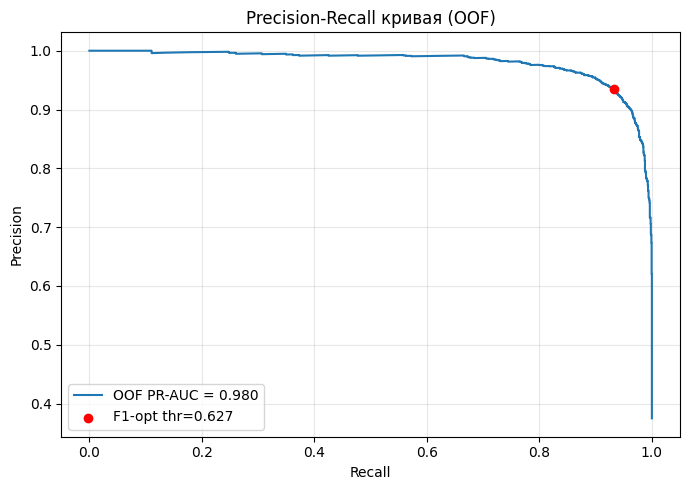


Сохранение порог: 0.6269


In [8]:
# Метрики на OOF
oof_pr_auc = average_precision_score(y_train, oof_preds)
oof_roc_auc = roc_auc_score(y_train, oof_preds)
oof_brier = brier_score_loss(y_train, oof_preds)

print("=== OOF (порог 0.5) ===")
print(f"PR-AUC:    {oof_pr_auc:.4f}")
print(f"ROC-AUC:   {oof_roc_auc:.4f}")
print(f"Brier:     {oof_brier:.4f}  (меньше = лучше)")
print(f"Precision: {precision_score(y_train, oof_preds > 0.5):.4f}")
print(f"Recall:    {recall_score(y_train, oof_preds > 0.5):.4f}")
print(f"F1:        {f1_score(y_train, oof_preds > 0.5):.4f}")

# Подбор порога по F1
prec, rec, thresholds = precision_recall_curve(y_train, oof_preds)
f1s = 2 * prec * rec / (prec + rec + 1e-10)
best_f1_idx = int(np.argmax(f1s[:-1]))  # последняя точка thresholds не имеет
best_thr = float(thresholds[best_f1_idx])

print(f"\n=== OOF (порог {best_thr:.4f}, F1-оптимальный) ===")
print(f"Precision: {prec[best_f1_idx]:.4f}")
print(f"Recall:    {rec[best_f1_idx]:.4f}")
print(f"F1:        {f1s[best_f1_idx]:.4f}")

# Кривая PR
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(rec, prec, label=f"OOF PR-AUC = {oof_pr_auc:.3f}")
ax.scatter(rec[best_f1_idx], prec[best_f1_idx], color="red", zorder=3,
           label=f"F1-opt thr={best_thr:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall кривая (OOF)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nСохранение порог: {best_thr:.4f}")

### Финальная модель на всём train и holdout-предсказания

In [9]:
n_estimators_final = int(np.median(best_iters))
final_params = {**lgb_params, "n_estimators": n_estimators_final}

final_model = lgb.LGBMClassifier(**final_params)
final_model.fit(X_train, y_train)

# Предсказания на holdout
X_test = X.iloc[test_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)
groups_test = groups.iloc[test_idx].reset_index(drop=True)

test_preds = final_model.predict_proba(X_test)[:, 1]

print(f"Финальная модель обучена: n_estimators={n_estimators_final}")
print(f"Holdout: {len(y_test)} строк, положительных: {int(y_test.sum())}")

Финальная модель обучена: n_estimators=264
Holdout: 1465 строк, положительных: 549


### Метрики на holdout

=== HOLDOUT (порог 0.5) ===
PR-AUC:    0.9845
ROC-AUC:   0.9899
Brier:     0.0342
Precision: 0.9185
Recall:    0.9654
F1:        0.9414

=== HOLDOUT (порог 0.6269 из OOF) ===
[[886  30]
 [ 31 518]]
              precision    recall  f1-score   support

           0      0.966     0.967     0.967       916
           1      0.945     0.944     0.944       549

    accuracy                          0.958      1465
   macro avg      0.956     0.955     0.956      1465
weighted avg      0.958     0.958     0.958      1465



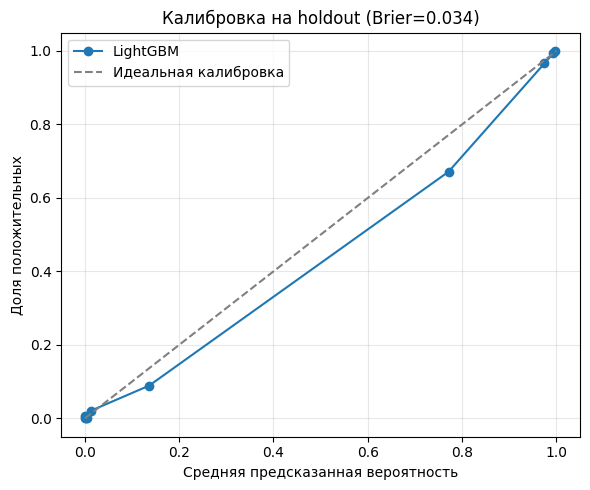

In [10]:
print("=== HOLDOUT (порог 0.5) ===")
print(f"PR-AUC:    {average_precision_score(y_test, test_preds):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_preds):.4f}")
print(f"Brier:     {brier_score_loss(y_test, test_preds):.4f}")
print(f"Precision: {precision_score(y_test, test_preds > 0.5):.4f}")
print(f"Recall:    {recall_score(y_test, test_preds > 0.5):.4f}")
print(f"F1:        {f1_score(y_test, test_preds > 0.5):.4f}")

y_pred_thr = (test_preds > best_thr).astype(int)
print(f"\n=== HOLDOUT (порог {best_thr:.4f} из OOF) ===")
print(confusion_matrix(y_test, y_pred_thr))
print(classification_report(y_test, y_pred_thr, digits=3, zero_division=0))

# Калибровка: насколько предсказанные вероятности совпадают с реальностью
prob_true, prob_pred = calibration_curve(y_test, test_preds, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, marker="o", label="LightGBM")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Идеальная калибровка")
ax.set_xlabel("Средняя предсказанная вероятность")
ax.set_ylabel("Доля положительных")
ax.set_title(f"Калибровка на holdout (Brier={brier_score_loss(y_test, test_preds):.3f})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### feature importance

In [11]:
fi = pd.DataFrame({
    "feature": X_train.columns,
    "gain": final_model.booster_.feature_importance(importance_type="gain"),
    "split": final_model.booster_.feature_importance(importance_type="split"),
}).sort_values("gain", ascending=False).reset_index(drop=True)

print("Топ-20 признаков по gain:")
display(fi.head(20))

fi.to_csv(SAVE_DIR / "feature_importance.csv", index=False)

Топ-20 признаков по gain:


,feature,gain,split
0,koi_smet_err2,25678.677354,136
1,koi_prad,20162.987875,257
2,koi_max_mult_ev,17029.606767,402
3,koi_dor,11130.689439,323
4,koi_count,9211.904864,245
5,koi_ror,4814.055266,244
6,koi_duration_err1,4350.286978,333
7,koi_num_transits,2640.618611,184
8,koi_duration_err2,2240.114789,174
9,koi_srho_err1,2216.715794,334


### Сохранение

In [12]:
# Финальная модель
joblib.dump(final_model, SAVE_DIR / "lgbm_final.pkl")

# OOF-предсказания (для стекинга)
pd.DataFrame({
    "train_local_idx": np.arange(len(X_train)),
    "kepid": groups_train.values,
    "y_true": y_train.values,
    "oof_pred": oof_preds,
}).to_csv(SAVE_DIR / "lgbm_oof_preds.csv", index=False)

# Holdout-предсказания (для финальной оценки)
pd.DataFrame({
    "test_local_idx": np.arange(len(X_test)),
    "kepid": groups_test.values,
    "y_true": y_test.values,
    "pred": test_preds,
}).to_csv(SAVE_DIR / "lgbm_test_preds.csv", index=False)

# Метаданные (порог, метрики, best_iters)
pd.DataFrame([{
    "best_thr": best_thr,
    "oof_pr_auc": oof_pr_auc,
    "oof_roc_auc": oof_roc_auc,
    "oof_brier": oof_brier,
    "test_pr_auc": average_precision_score(y_test, test_preds),
    "test_roc_auc": roc_auc_score(y_test, test_preds),
    "test_brier": brier_score_loss(y_test, test_preds),
    "n_estimators_final": n_estimators_final,
    "median_best_iter_cv": int(np.median(best_iters)),
}]).to_csv(SAVE_DIR / "lgbm_metadata.csv", index=False)

print("Сохранено в", SAVE_DIR.resolve())
for f in ["lgbm_final.pkl", "lgbm_oof_preds.csv", "lgbm_test_preds.csv",
          "lgbm_metadata.csv", "feature_importance.csv"]:
    print(f"  - {f}")

Сохранено в C:\Users\Vladislav\.vscode\ML\exoplanet-detector\data\physical_signs_final
  - lgbm_final.pkl
  - lgbm_oof_preds.csv
  - lgbm_test_preds.csv
  - lgbm_metadata.csv
  - feature_importance.csv


## Временный вывод
### Слишком большие результаты
Значения всех метрик превышают 90%, как и в первой версии ноутбука с моделями, что очень подозрительно. В качестве утечки рассматриваются фичи *_err* и *MES*.